In [1]:
import pandas as pd
import numpy as np
import joblib

from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    classification_report,
    confusion_matrix
)

from xgboost import XGBClassifier

import matplotlib.pyplot as plt

In [2]:
transactions = pd.read_csv(
    "C:/Users/lenovo/Desktop/FinRisk-X/data/raw/transactions.csv"
)

transactions["timestamp"] = pd.to_datetime(
    transactions["timestamp"]
)

transactions = transactions.sort_values(
    ["customer_id", "timestamp"]
).reset_index(drop=True)

print("Shape:", transactions.shape)
transactions.head()

Shape: (200000, 12)


,transaction_id,customer_id,timestamp,transaction_type,merchant_id,merchant_category,device_id,is_fraud,amount,hour,day_of_week,is_weekend
0,1042065,100001,2025-03-29 21:37:35,Card,11346,Financial,20714,0,13351.43,21,5,1
1,968859,100001,2025-05-04 10:28:58,Card,10253,Healthcare,20821,0,4474.74,10,6,1
2,1025968,100001,2025-05-07 06:23:39,UPI,11753,Electronics,22961,0,11412.17,6,2,0
3,940082,100001,2025-05-08 15:05:13,Card,11663,Travel,22245,0,2012.79,15,3,0
4,915192,100001,2025-05-16 13:25:24,UPI,10372,Retail,22056,0,398.77,13,4,0


In [3]:
transactions["customer_mean_amount"] = (
    transactions
    .groupby("customer_id")["amount"]
    .transform("mean")
)

transactions["customer_std_amount"] = (
    transactions
    .groupby("customer_id")["amount"]
    .transform("std")
)

transactions["customer_median_amount"] = (
    transactions
    .groupby("customer_id")["amount"]
    .transform("median")
)

In [4]:
transactions["amount_deviation"] = (
    (transactions["amount"] - transactions["customer_median_amount"])
    / (transactions["customer_std_amount"] + 1)
)

transactions["amount_deviation"] = (
    transactions["amount_deviation"]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

In [5]:
transactions["previous_timestamp"] = (
    transactions
    .groupby("customer_id")["timestamp"]
    .shift(1)
)

transactions["seconds_since_previous"] = (
    transactions["timestamp"]
    - transactions["previous_timestamp"]
).dt.total_seconds()

transactions["seconds_since_previous"] = (
    transactions["seconds_since_previous"]
    .fillna(86400)
)

In [6]:
transactions["date"] = transactions["timestamp"].dt.date

transactions["transactions_24h"] = (
    transactions
    .groupby(["customer_id", "date"])["transaction_id"]
    .transform("count")
)

In [7]:
transactions["spending_24h"] = (
    transactions
    .groupby(["customer_id", "date"])["amount"]
    .transform("sum")
)

In [8]:
transactions["previous_device"] = (
    transactions
    .groupby("customer_id")["device_id"]
    .shift(1)
)

transactions["device_changed"] = (
    transactions["device_id"]
    != transactions["previous_device"]
).astype(int)

In [10]:
print(transactions.columns.tolist())

['transaction_id', 'customer_id', 'timestamp', 'transaction_type', 'merchant_id', 'merchant_category', 'device_id', 'is_fraud', 'amount', 'hour', 'day_of_week', 'is_weekend', 'customer_mean_amount', 'customer_std_amount', 'customer_median_amount', 'amount_deviation', 'previous_timestamp', 'seconds_since_previous', 'date', 'transactions_24h', 'spending_24h', 'previous_device', 'device_changed']


In [11]:
# Device change detection

transactions["previous_device"] = (
    transactions
    .groupby("customer_id")["device_id"]
    .shift(1)
)

transactions["device_changed"] = (
    transactions["device_id"]
    != transactions["previous_device"]
).astype(int)

# First transaction for each customer is not considered a device change
transactions.loc[
    transactions["previous_device"].isna(),
    "device_changed"
] = 0

print("Device-change feature created.")

Device-change feature created.


In [12]:
fraud_features = [
    "amount",
    "hour",
    "day_of_week",
    "is_weekend",
    "amount_deviation",
    "seconds_since_previous",
    "transactions_24h",
    "spending_24h",
    "device_changed"
]

missing = [
    col for col in fraud_features
    if col not in transactions.columns
]

if missing:
    raise ValueError(f"Missing fraud features: {missing}")

print("All fraud features available.")

All fraud features available.


In [13]:
model_data = pd.get_dummies(
    transactions,
    columns=[
        "transaction_type",
        "merchant_category"
    ],
    drop_first=False
)

In [14]:
categorical_features = [
    col
    for col in model_data.columns
    if col.startswith("transaction_type_")
    or col.startswith("merchant_category_")
]

final_fraud_features = (
    fraud_features +
    categorical_features
)

print("Number of fraud features:", len(final_fraud_features))

Number of fraud features: 23


In [15]:
isolation_features = [
    "amount",
    "hour",
    "day_of_week",
    "is_weekend",
    "amount_deviation",
    "seconds_since_previous",
    "transactions_24h",
    "spending_24h",
    "device_changed"
]

In [16]:
X = model_data[final_fraud_features].copy()
y = model_data["is_fraud"].copy()

X = X.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

print("X:", X.shape)
print("Fraud distribution:")
print(y.value_counts())
print(y.value_counts(normalize=True))

X: (200000, 23)
Fraud distribution:
is_fraud
0    193191
1      6809
Name: count, dtype: int64
is_fraud
0    0.965955
1    0.034045
Name: proportion, dtype: float64


In [17]:
split_time = transactions["timestamp"].quantile(0.80)

train_mask = transactions["timestamp"] <= split_time
test_mask = transactions["timestamp"] > split_time

X_train = X.loc[train_mask]
X_test = X.loc[test_mask]

y_train = y.loc[train_mask]
y_test = y.loc[test_mask]

print("Split time:", split_time)

print("Training:", X_train.shape)
print("Testing :", X_test.shape)

print("\nTrain fraud rate:")
print(y_train.mean())

print("\nTest fraud rate:")
print(y_test.mean())

Split time: 2025-10-18 16:20:41.600000
Training: (160000, 23)
Testing : (40000, 23)

Train fraud rate:
0.03410625

Test fraud rate:
0.0338


In [18]:
negative = (y_train == 0).sum()
positive = (y_train == 1).sum()

scale_pos_weight = negative / positive

print("scale_pos_weight:", scale_pos_weight)

scale_pos_weight: 28.320139270661535


In [19]:
fraud_xgb = XGBClassifier(
    n_estimators=250,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=scale_pos_weight,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1
)

fraud_xgb.fit(
    X_train,
    y_train
)

,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.8
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


In [20]:
xgb_prob = fraud_xgb.predict_proba(
    X_test
)[:, 1]

xgb_pred = (
    xgb_prob >= 0.5
).astype(int)

In [21]:
xgb_results = {
    "Precision": precision_score(
        y_test,
        xgb_pred,
        zero_division=0
    ),
    "Recall": recall_score(
        y_test,
        xgb_pred,
        zero_division=0
    ),
    "F1": f1_score(
        y_test,
        xgb_pred,
        zero_division=0
    ),
    "ROC-AUC": roc_auc_score(
        y_test,
        xgb_prob
    ),
    "PR-AUC": average_precision_score(
        y_test,
        xgb_prob
    )
}

xgb_results

{'Precision': 0.12092423176167018,
 'Recall': 0.7625739644970414,
 'F1': 0.20874670986029562,
 'ROC-AUC': 0.7890897524952875,
 'PR-AUC': 0.12638322153181372}

In [22]:
print(
    classification_report(
        y_test,
        xgb_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.99      0.81      0.89     38648
           1       0.12      0.76      0.21      1352

    accuracy                           0.80     40000
   macro avg       0.56      0.78      0.55     40000
weighted avg       0.96      0.80      0.87     40000



In [23]:
isolation_features = [
    "amount",
    "hour",
    "day_of_week",
    "is_weekend",
    "amount_deviation",
    "seconds_since_previous",
    "transactions_24h",
    "spending_24h",
    "device_changed"
]

In [24]:
scaler = MinMaxScaler()

X_iso_train = scaler.fit_transform(
    model_data.loc[
        train_mask,
        isolation_features
    ]
)

X_iso_test = scaler.transform(
    model_data.loc[
        test_mask,
        isolation_features
    ]
)

In [25]:
isolation_forest = IsolationForest(
    n_estimators=200,
    contamination=0.01,
    random_state=42,
    n_jobs=-1
)

isolation_forest.fit(
    X_iso_train
)

,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",200
,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",0.01
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [26]:
anomaly_raw = -isolation_forest.decision_function(
    X_iso_test
)

anomaly_scaler = MinMaxScaler()

anomaly_score = anomaly_scaler.fit_transform(
    anomaly_raw.reshape(-1, 1)
).ravel()

In [27]:
iso_auc = roc_auc_score(
    y_test,
    anomaly_score
)

iso_pr_auc = average_precision_score(
    y_test,
    anomaly_score
)

print(f"Isolation Forest ROC-AUC: {iso_auc:.4f}")
print(f"Isolation Forest PR-AUC:  {iso_pr_auc:.4f}")

Isolation Forest ROC-AUC: 0.5281
Isolation Forest PR-AUC:  0.0476


In [28]:
hybrid_score = (
    0.70 * xgb_prob
    + 0.30 * anomaly_score
)

In [29]:
hybrid_auc = roc_auc_score(
    y_test,
    hybrid_score
)

hybrid_pr_auc = average_precision_score(
    y_test,
    hybrid_score
)

print(f"Hybrid ROC-AUC: {hybrid_auc:.4f}")
print(f"Hybrid PR-AUC:  {hybrid_pr_auc:.4f}")

Hybrid ROC-AUC: 0.7868
Hybrid PR-AUC:  0.1258


In [30]:
fraud_comparison = pd.DataFrame({
    "Model": [
        "XGBoost Supervised",
        "Isolation Forest",
        "Hybrid Fraud Engine"
    ],
    "ROC-AUC": [
        xgb_results["ROC-AUC"],
        iso_auc,
        hybrid_auc
    ],
    "PR-AUC": [
        xgb_results["PR-AUC"],
        iso_pr_auc,
        hybrid_pr_auc
    ]
})

fraud_comparison

,Model,ROC-AUC,PR-AUC
0,XGBoost Supervised,0.789090,0.126383
1,Isolation Forest,0.528145,0.047590
2,Hybrid Fraud Engine,0.786801,0.125765


In [31]:
fraud_importance = pd.DataFrame({
    "Feature": final_fraud_features,
    "Importance": fraud_xgb.feature_importances_
})

fraud_importance = fraud_importance.sort_values(
    "Importance",
    ascending=False
)

fraud_importance.head(15)

,Feature,Importance
1,hour,0.477871
7,spending_24h,0.038180
0,amount,0.031609
3,is_weekend,0.026128
5,seconds_since_previous,0.025812
4,amount_deviation,0.025648
8,device_changed,0.024720
12,transaction_type_Online,0.024471
2,day_of_week,0.024132
21,merchant_category_Travel,0.023665


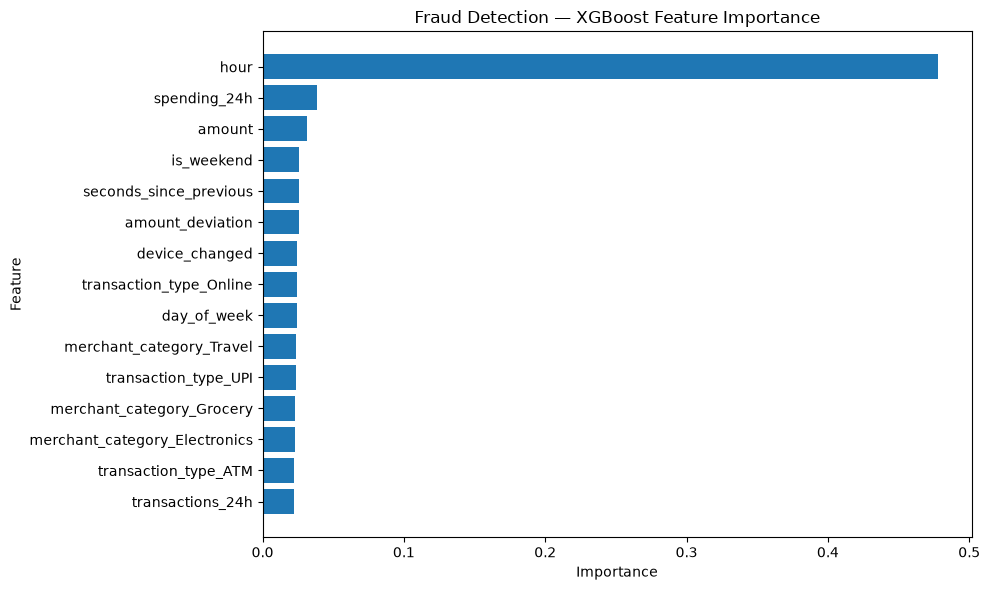

In [32]:
top_features = fraud_importance.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Fraud Detection — XGBoost Feature Importance")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [33]:
hybrid_pred = (
    hybrid_score >= 0.5
).astype(int)

cm = confusion_matrix(
    y_test,
    hybrid_pred
)

print(cm)

[[31190  7458]
 [  333  1019]]


In [34]:
print(
    classification_report(
        y_test,
        hybrid_pred,
        zero_division=0
    )
)

              precision    recall  f1-score   support

           0       0.99      0.81      0.89     38648
           1       0.12      0.75      0.21      1352

    accuracy                           0.81     40000
   macro avg       0.55      0.78      0.55     40000
weighted avg       0.96      0.81      0.87     40000



In [35]:
joblib.dump(
    fraud_xgb,
    "../models/fraud_xgb_model.pkl"
)

joblib.dump(
    isolation_forest,
    "../models/fraud_isolation_forest.pkl"
)

joblib.dump(
    scaler,
    "../models/fraud_scaler.pkl"
)

joblib.dump(
    anomaly_scaler,
    "../models/fraud_anomaly_scaler.pkl"
)

joblib.dump(
    final_fraud_features,
    "../models/fraud_feature_columns.pkl"
)

fraud_comparison.to_csv(
    "../data/processed/fraud_model_comparison.csv",
    index=False
)

fraud_importance.to_csv(
    "../data/processed/fraud_feature_importance.csv",
    index=False
)

print("All fraud detection artifacts saved successfully.")

All fraud detection artifacts saved successfully.


In [36]:
transactions.to_csv(
    "../data/processed/fraud_transaction_features.csv",
    index=False
)

print("Fraud transaction feature dataset saved.")

Fraud transaction feature dataset saved.
